# PISA Example Using Public IceCube Data


Dataset must be obtained from the PRD 2023 paper of IceCube

https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/B4RITM&version=1.0

## Added the option to set the calibration file in PISA - check the results



In [1]:
import numpy as np
from uncertainties import unumpy as unp
import matplotlib.pyplot as plt
import copy
import os
import pisa
from pisa.core.distribution_maker import DistributionMaker
from pisa.core.pipeline import Pipeline
from pisa.analysis.analysis import Analysis
from pisa import FTYPE, ureg

<< PISA is running in double precision (FP64) mode; numba is running on CPU (single core) >>


In [2]:
fridge_path = '/home/jp/icecube/wg-oscillations-fridge/analysis'

In [3]:
os.environ['PISA_RESOURCES'] = fridge_path

In [4]:
myfiles_path = '/home/jp/daemonflux/oscillations_release_2023'

In [5]:
## Model

We can now instantiate the `model` (given our configs) that we later fit to data. This now containes two `Pipelines` in a `DistributionMaker`, one for our neutrinos, and one for the background muons.

In [6]:
model = DistributionMaker([
    os.path.join(myfiles_path,"pisa_settings/pipeline/neutrino_pipeline_daemon_nothresholds.cfg"),
    os.path.join(myfiles_path,"pisa_settings/pipeline/muon_pipeline.cfg")
])

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")

Calibration file /home/jp/daemonflux/fit_results/surface_only/surface_daemonflux_nothresholds.pkl
[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")



In [7]:
## Verifying that there are things loaded
#model.pipelines[0].data['numu_cc']['true_energy']
#model.pipelines[1].data['icc']['reco_energy']
#model.pipelines[2].data['total']['reco_energy']

In [8]:
# Confirming that the data has been loaded
loader = model.pipelines[0]
loader

stage number,name,calc_mode,apply_mode,has setup,has compute,has apply,# fixed params,# free params
0,csv_loader,events,events,True,False,True,0,0
1,daemon_flux,events,events,True,True,False,2,24
2,prob3,"""osc_binning"": 300 (true_energy) x 68 (true_coszen)",events,True,True,True,10,2
3,genie_sys,,events,True,False,True,0,2
4,dis_sys,,events,True,False,True,0,1
5,nutau_xsec,events,events,True,True,True,1,0
6,aeff,,events,False,False,True,3,2
7,hist,events,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,False,True,0,0
8,csv_hypersurfaces,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)","""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,True,True,0,6
9,fix_error,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)","""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,True,True,0,0


Our model has a number of free parameters, that will be used in our fit to the data

In [9]:
model.params.free

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False


The two pipelines are quite different, with most complexity in the neutrino pipeline, that has several `Stage`s and free parameters:

In [10]:
model.pipelines[0].stages[1].params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_K_2P,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_K_31G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_antiK_158G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_antiK_2P,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_antiK_31G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_n_158G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_n_2P,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_p_158G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_p_2P,0,0,"[-3.0, 3.0]",+/- 1.0,1,False


While the muon pipleine is rather simple

## Get data

In [11]:
# real data
data_maker = Pipeline(os.path.join(myfiles_path,"pisa_settings/pipeline/data_pipeline.cfg"))
data = data_maker.get_outputs()

## Fitting

For fitting we need to configure a minimizer, several standard cfgs are available, but you can also define your own.
For the fit we need to choose a `metric`, and by default, theta23 octants, which are quasi degenerate, are fit seperately, which means two fits are run.

In [40]:
# Start from a previuos fit
if True:
    import json
    presults_file = '/home/jp/daemonflux/oscillations_release_2023/pisa_results/pfix_daemonflux_full_nothresholds.json'
    presults = json.load(open(presults_file))
    for one_param in presults['params']:
        if not one_param['is_fixed']:
            model.params.free[one_param['name']].value = one_param['value']
        
    

In [41]:
model.params.free

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0.262972,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,1.33149,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_31G,-0.183114,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0.0548888,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,1.34585,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_31G,-0.0256246,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,-0.0546788,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_2P,0.0172529,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_158G,0.0285564,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_2P,0.0762301,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False


In [42]:
local_fit_minuit = {
    "method": "iminuit",
    "method_kwargs": {
        "errors": 0.1,
        "precision": 1e-14,  # default: double precision
        "tol": 1e-2,  # default: 0.1
        "run_simplex": False,
        "run_migrad": True
    },
    "local_fit_kwargs": None
}

In [43]:
fit_octant = {
    "method": "octants",
    "method_kwargs": {
        "angle": "theta23",
        "inflection_point": 45 * ureg.degrees,
    },
    "local_fit_kwargs": local_fit_minuit
}

In [44]:
ana = Analysis()
ana.pprint=True

In [ ]:
result = ana.fit_recursively(
    data_dist=data,
    hypo_maker=model,
    metric='chi2',
    external_priors_penalty=None,
    **fit_octant,
)

[ WARNING] /home/jp/software/pisa/pisa/stages/flux/daemon_flux.py:174: NumbaWarning: 
Compilation is falling back to object mode WITHOUT looplifting enabled because Function "make_2d_flux_map" failed type inference due to: non-precise type pyobject
During: typing of argument at /home/jp/software/pisa/pisa/stages/flux/daemon_flux.py (189)

File "../pisa/stages/flux/daemon_flux.py", line 189:
def make_2d_flux_map(flux_obj,
    <source elided>

    for index in range(len(icangles)):
    ^

  @jit(forceobj=True)

                                                                                                                                                                                                                                                                                                                                                            (deg)       (eV**2)                                                                                                                      

Here we can view the bestfit parameters - the result of our fit.
We have run two fits (separately for each theta23 octant), and the best result is stored in `results[0]` (both fits are also available under `results[1]`)

In [47]:
result.metric_val

207.69142741226412

In [48]:
result.params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0.2629585489671751,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,1.3313834433731886,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_31G,-0.18310726936618238,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0.05489380435875102,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,1.3456987194666308,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_31G,-0.02562849914667087,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,-0.05474144064838349,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_2P,0.017140542123611713,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_158G,0.028586849466655018,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_2P,0.07626779899481129,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False


In [49]:
print(np.sin(np.deg2rad(result['params']['theta23'].value))**2, "||| 0.51+/-0.05")
print((result['params']['deltam31'].value-result['params']['deltam21'].value)*1E3, "||| 2.41+/-0.07")

0.5157754282684137 dimensionless ||| 0.51+/-0.05
2.381108711990094 electron_volt ** 2 ||| 2.41+/-0.07


In [50]:
# Copy parameters and update the model 

bestfit_params = result['params'].free
model.update_params(copy.deepcopy(bestfit_params))


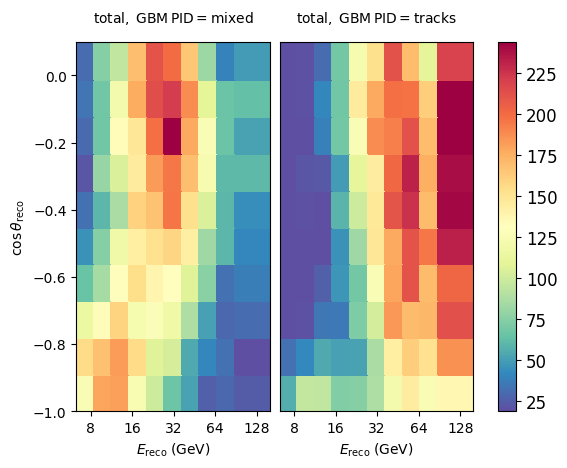

In [51]:
data.plot()

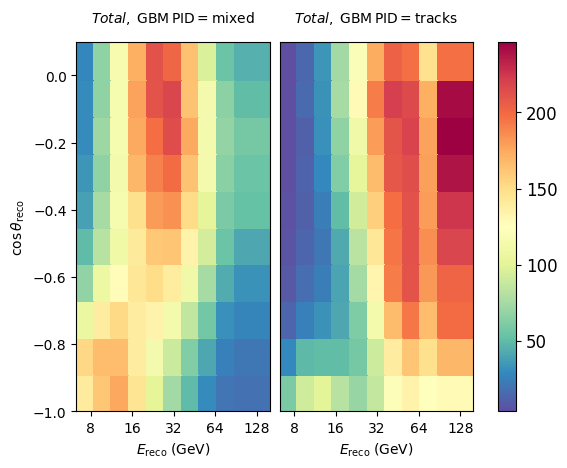

In [21]:
template = model.get_outputs(return_sum=True)
template.plot()

Let's see how good that fit looks like. We here construct signed mod_chi2 maps by hand.
You can see that after the fit, it improved considerably, and the distribution of chi2 values is now more uniform - not much features can be seen anymore.

Evaluating other metrics just for fun:

In [52]:
for metric in pisa.utils.stats.ALL_METRICS:
    try:
        print('%s = %.3f'%(metric,data.metric_total(bestfit, metric)))
    except:
        print('%s failed'%metric)

llh failed
conv_llh failed
barlow_llh failed
mcllh_mean failed
mcllh_eff failed
generalized_poisson_llh failed
chi2 failed
mod_chi2 failed
correct_chi2 failed
weighted_chi2 failed


Adding prior penalty terms

## Storing the results to a file

Since the fit took a while, it might be useful to store the results to a file. (NB: in this example we use a temp file, but in real life you would of course just use a real pathname instead!)

In [53]:
outdir = '/home/jp/daemonflux/oscillations_release_2023/pisa_results/'
filename = 'pfix_daemonflux_full_nothresholds_native.json'
pisa.utils.fileio.to_file(result, outdir+filename)

[ WARNING] Directory "/home/jp/daemonflux/oscillations_release_2023/pisa_results" already exists
[ WARNING] Overwriting file at '/home/jp/daemonflux/oscillations_release_2023/pisa_results/pfix_daemonflux_full_nothresholds_native.json'


To reload, we can read the file. But to get PISA objects back, they need to instantiated